# Parte 2 - Métodos multidimensionais e reflexão

**Tiago Oliveira Lima (564988) e Noberto Frota Oliveira Nogueira (568044)** · UFC · Ricardo Coelho · 16/11/2026.

Implementações em `codigo/otimizacao.py` e `codigo/busca_linear.py`. Não há otimizador pronto nem busca 1D de biblioteca. A busca Goldstein é reutilizada do código anterior e sua origem está em `fontes/manifesto.json`. As 24 execuções principais usam os critérios sugeridos; 24 execuções adicionais isolam a parada por gradiente. A Parte 1 não faz parte deste notebook.

Execute todas as células a partir desta pasta. O relatório inclui manual, análise e limites. A distribuição de responsabilidades foi declarada pelo usuário em 17/11/2026 e está registrada ao final.

## Funções e pontos iniciais

Catálogo original: `fontes/catalogo_primeira_atividade.pdf`, páginas 4-6. A potência e os denominadores do TP14 foram conferidos visualmente.

|TP|Função|A|B|
|---|---|---|---|
|3|$x_1^2+2x_2^2+3x_3^2-2x_1x_2$|(1,1,1)|(-1,-1,-1)|
|14|$0.1[12+x_1^2+(1+x_2^2)/x_1^2+(x_1^2x_2^2+100)/(x_1^4x_2^4)]$|(.5,.5)|(-.5,-.5)|
|9|$1000(x_2-x_1^2)^2+(1-x_1)^2$|(-1.2,1)|(1.2,-1)|
|16|$(x_1+10x_2)^2+5(x_3-x_4)^2+(x_2-2x_3)^4+10(x_1-x_4)^4$|(3,-1,0,1)|(-3,1,0,-1)|

TP14: domínio $x_1x_2\ne0$. TP16: mínimo com Hessiana singular.

## Algoritmos

Gradiente: $d_k=-g_k$. BFGS inversa: $H_0=I$, $d_k=-H_kg_k$, $H_{k+1}=(I-\rho sy^T)H_k(I-\rho ys^T)+\rho ss^T$, $\rho=(s^Ty)^{-1}$, $s=x_{k+1}-x_k$, $y=g_{k+1}-g_k$. Atualização omitida se não houver curvatura segura.

FR: $\beta=\|g_{k+1}\|^2/\|g_k\|^2$, $d_{k+1}=-g_{k+1}+\beta d_k$. Reinício a cada dimensão n e quando faltar descida; cada evento é registrado.

Goldstein: $f_k+(1-c)\alpha g_k^Td_k\le f(x_k+\alpha d_k)\le f_k+c\alpha g_k^Td_k$, $c=0.1$. Esta busca não impõe Wolfe forte; os resultados são experimentais, sem atribuir automaticamente a garantia teórica clássica de FR.

In [1]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd() / "codigo"))
from testar import validar
validacao = validar()
validacao

{'TP3': {'pontos': [[1.0, 1.0, 1.0],
   [-1.0, -1.0, -1.0],
   [0.9086675242506013, 0.975485144228297, 0.9222492522198444],
   [0.9680311712856046, 0.9667941201502037, 0.8891126627412613],
   [1.1042745800768718, 0.9248588423453242, 0.8961501239535813],
   [0.9861314759693228, 0.8912873321655537, 0.8864634039400533]],
  'max_erro_gradiente': 5.828452592983411e-12,
  'max_erro_hessiana': 8.251917667697247e-12},
 'TP14': {'pontos': [[0.5, 0.5],
   [-0.5, -0.5],
   [0.4152468216196165, 0.5933877223379722],
   [0.6143326690747818, 0.6380579580370679],
   [0.6407282697370376, 0.47812454908820534],
   [0.37269957576173995, 0.5662326439301895]],
  'max_erro_gradiente': 3.600135970178021e-09,
  'max_erro_hessiana': 5.039565495000286e-09},
 'TP9': {'pontos': [[-1.2, 1.0],
   [1.2, -1.0],
   [-1.264184380676866, 0.8878448089355507],
   [-1.0822494654583972, 1.1215268899552466],
   [-1.080193216417606, 1.0373334508397767],
   [-1.1691054852297218, 1.1040260093645509]],
  'max_erro_gradiente': 1.9

## Matriz principal

Parada por gradiente ≤ 1e-5 **ou** variação relativa ≤ 1e-7 **ou** 1000 passos. Variação e limite não são certificados de convergência.

In [2]:
from executar import executar
resultados = executar([])

TP3 Gradiente A 28 variacao_objetivo f=1.2809801e-07 g=0.000559
TP3 Gradiente B 28 variacao_objetivo f=1.2809801e-07 g=0.000559
TP3 BFGS A 6 variacao_objetivo f=1.2291812e-11 g=1.09e-05
TP3 BFGS B 6 variacao_objetivo f=1.2291812e-11 g=1.09e-05
TP3 FR A 18 variacao_objetivo f=2.6559288e-09 g=9.06e-05
TP3 FR B 18 variacao_objetivo f=2.6559288e-09 g=9.06e-05
TP14 Gradiente A 12 variacao_objetivo f=1.7441521 g=0.000226
TP14 Gradiente B 12 variacao_objetivo f=1.7441521 g=0.000226
TP14 BFGS A 28 gradiente f=1.744152 g=1.04e-07
TP14 BFGS B 28 gradiente f=1.744152 g=1.04e-07
TP14 FR A 9 variacao_objetivo f=1.7441521 g=0.000243
TP14 FR B 9 variacao_objetivo f=1.7441521 g=0.000243
TP9 Gradiente A 102 variacao_objetivo f=8.3085518e-06 g=0.00518


TP9 Gradiente B 1000 limite_iteracoes f=0.12954886 g=0.568
TP9 BFGS A 60 variacao_objetivo f=7.054143e-12 g=0.000305
TP9 BFGS B 43 variacao_objetivo f=1.8917251e-09 g=0.00404


TP9 FR A 209 variacao_objetivo f=7.7496567e-07 g=0.00327
TP9 FR B 89 variacao_objetivo f=0.00023321924 g=0.031


TP16 Gradiente A 1000 limite_iteracoes f=0.00017477252 g=0.00856


TP16 Gradiente B 1000 limite_iteracoes f=0.00017477252 g=0.00856
TP16 BFGS A 21 variacao_objetivo f=3.0783937e-08 g=7.45e-05
TP16 BFGS B 21 variacao_objetivo f=3.0783937e-08 g=7.45e-05
TP16 FR A 72 variacao_objetivo f=6.9967653e-07 g=0.00348
TP16 FR B 72 variacao_objetivo f=6.9967653e-07 g=0.00348


In [3]:
from IPython.display import HTML, display, Image
from html import escape
cab = ['TP','Método','A/B','Ponto final','f','Norma g','k','f/g','Parada']
linhas = []
for r in resultados:
    v=[r['problema'],r['metodo'],r['ponto'],str(r['x_final']),f"{r['f_final']:.8g}",f"{r['norma_grad_final']:.4g}",r['iteracoes'],str(r['avaliacoes_f'])+'/'+str(r['avaliacoes_g']),r['status']]
    linhas.append('<tr>'+''.join('<td>'+escape(str(x))+'</td>' for x in v)+'</tr>')
display(HTML('<table><tr>'+''.join('<th>'+x+'</th>' for x in cab)+'</tr>'+''.join(linhas)+'</table>'))

TP,Método,A/B,Ponto final,f,Norma g,k,f/g,Parada
TP3,Gradiente,A,"[0.0004706382751464844, 0.00029087066650390625, 6.103515625e-05]",1.2809801e-07,0.0005592,28,78/29,variacao_objetivo
TP3,Gradiente,B,"[-0.0004706382751464844, -0.00029087066650390625, -6.103515625e-05]",1.2809801e-07,0.0005592,28,78/29,variacao_objetivo
TP3,BFGS,A,"[2.5060291091690337e-06, -8.737100593065759e-07, -1.8779924686635223e-07]",1.2291812e-11,1.092e-05,6,11/7,variacao_objetivo
TP3,BFGS,B,"[-2.5060291091690337e-06, 8.737100593065759e-07, 1.8779924686635223e-07]",1.2291812e-11,1.092e-05,6,11/7,variacao_objetivo
TP3,FR,A,"[-6.626254972144672e-05, -3.903271960440323e-05, 1.141507672522181e-05]",2.6559288e-09,9.063e-05,18,45/19,variacao_objetivo
TP3,FR,B,"[6.626254972144672e-05, 3.903271960440323e-05, -1.141507672522181e-05]",2.6559288e-09,9.063e-05,18,45/19,variacao_objetivo
TP14,Gradiente,A,"[1.7433060479634157, 2.030318855300082]",1.7441521,0.0002263,12,40/13,variacao_objetivo
TP14,Gradiente,B,"[-1.7433060479634157, -2.030318855300082]",1.7441521,0.0002263,12,40/13,variacao_objetivo
TP14,BFGS,A,"[1.7434520459108087, 2.029694992842563]",1.744152,1.036e-07,28,50/29,gradiente
TP14,BFGS,B,"[-1.7434520459108087, -2.029694992842563]",1.744152,1.036e-07,28,50/29,gradiente


## Sequências de pontos

Amostra de início/fim de cada uma das 24 sequências abaixo. Todos os pontos, direções, passos, avaliações e tentativas de busca estão nos arquivos JSON (ou JSON.gz) em `resultados/parte2`. Não há encadeamento entre métodos.

In [4]:
for r in resultados:
    print('\n',r['problema'],r['metodo'],r['ponto'])
    t=r['trajetoria']
    for k in sorted(set(list(range(min(3,len(t))))+list(range(max(0,len(t)-2),len(t))))):
        z=t[k]
        print(z['k'],z['x'],'f=',z['f'],'norma_g=',z['norma_grad'])


 TP3 Gradiente A
0 [1.0, 1.0, 1.0] f= 4.0 norma_g= 6.324555320336759
1 [1.0, 0.5, -0.5] f= 1.25 norma_g= 3.1622776601683795
2 [0.75, 0.5, 0.25] f= 0.5 norma_g= 1.6583123951777
27 [0.0005817413330078125, 0.00035953521728515625, -0.0001220703125] f= 2.23344613914378e-07 norma_g= 0.0008996561359656096
28 [0.0004706382751464844, 0.00029087066650390625, 6.103515625e-05] f= 1.2809800864488352e-07 norma_g= 0.0005592419700607814

 TP3 Gradiente B
0 [-1.0, -1.0, -1.0] f= 4.0 norma_g= 6.324555320336759
1 [-1.0, -0.5, 0.5] f= 1.25 norma_g= 3.1622776601683795
2 [-0.75, -0.5, -0.25] f= 0.5 norma_g= 1.6583123951777
27 [-0.0005817413330078125, -0.00035953521728515625, 0.0001220703125] f= 2.23344613914378e-07 norma_g= 0.0008996561359656096
28 [-0.0004706382751464844, -0.00029087066650390625, -6.103515625e-05] f= 1.2809800864488352e-07 norma_g= 0.0005592419700607814

 TP3 BFGS A
0 [1.0, 1.0, 1.0] f= 4.0 norma_g= 6.324555320336759
1 [1.0, 0.5, -0.5] f= 1.25 norma_g= 3.1622776601683795
2 [0.310344827586

## TP3 - interpretação

O mínimo global único é a origem. A Hessiana constante tem autovalores 3−√5, 3+√5 e 6, todos positivos, e condição espectral 7,8541. A coercividade garante existência; a definição positiva garante unicidade. Assim, ambos os pontos pertencem à região de atração observada do mesmo mínimo. A conclusão usa esta função específica, não apenas convexidade.

A simetria f(−x)=f(x), o gradiente ímpar e a inicialização H0=I tornam as trajetórias refletidas para os algoritmos implementados. Os custos, passos e números de iterações A/B coincidem. Com parada apenas por gradiente, BFGS necessita 7 passos, FR 22 e gradiente 42. A parada sugerida por variação encerra mais cedo (6, 18 e 28), ainda com norma acima de 10⁻⁵.

No gradiente clássico, 88,9% dos pares de direções consecutivas do experimento principal têm produto interno negativo (cosseno mediano −0,406): há alternância compatível com ziguezague. Goldstein é inexata; não se afirma ortogonalidade exata entre direções consecutivas.

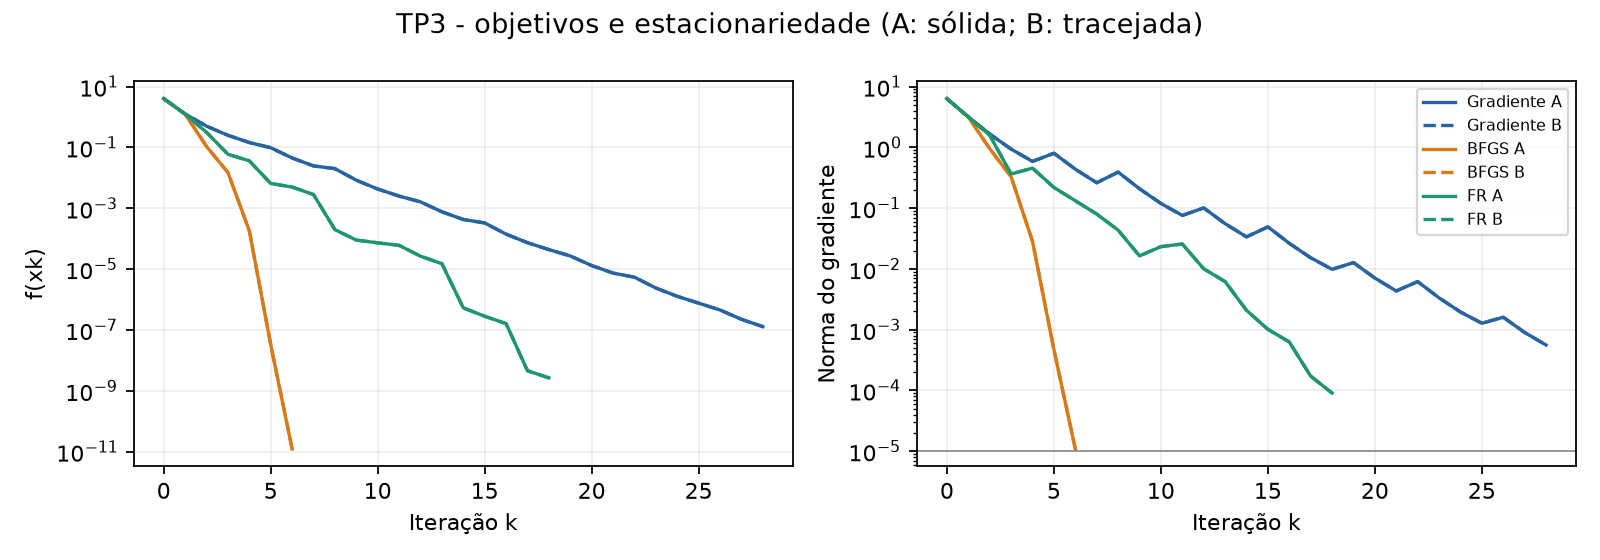

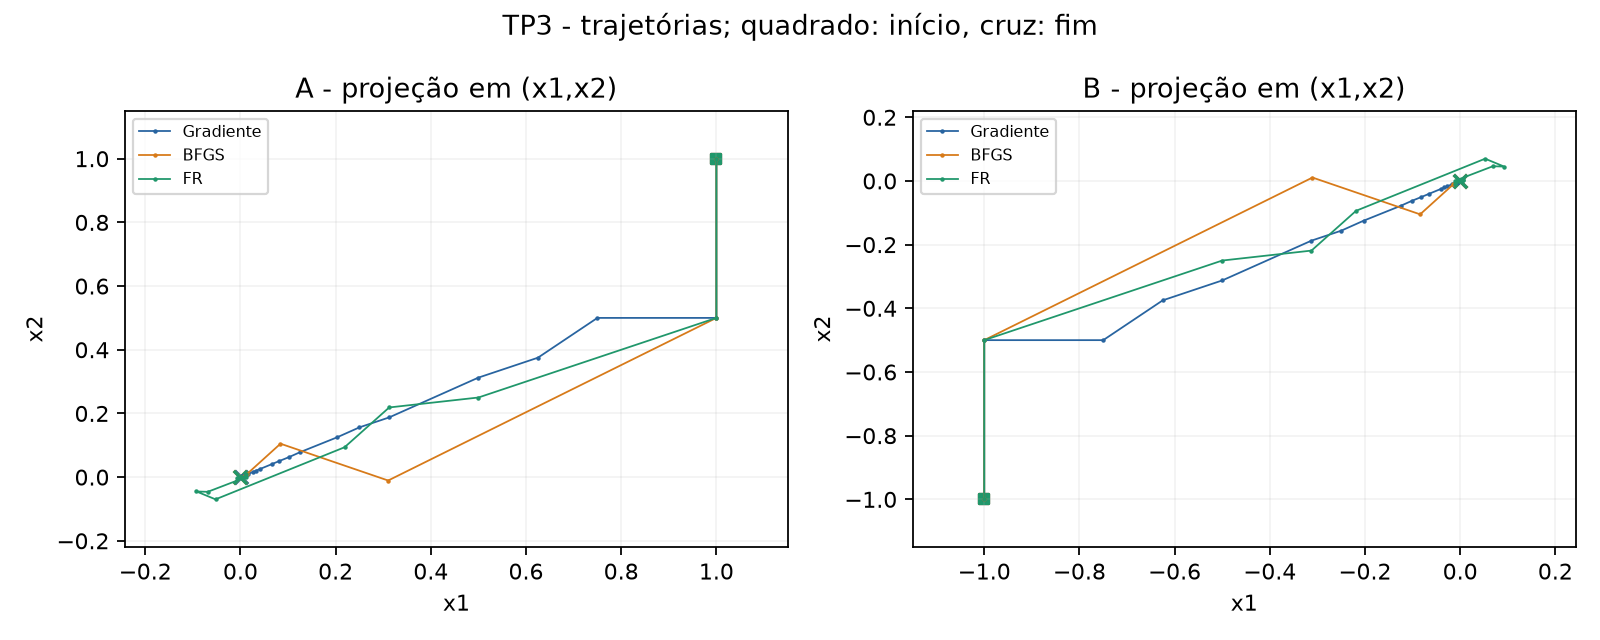

In [5]:
display(Image(filename='resultados/parte2/TP3_evolucao.png'))
display(Image(filename='resultados/parte2/TP3_trajetorias.png'))

## TP14 - interpretação

A função exclui x1=0 e x2=0. Ela depende somente dos quadrados: a reflexão de todas as coordenadas preserva o custo e reflete as trajetórias. Nas execuções, A permanece no primeiro quadrante e B no terceiro. Ambos chegam a soluções com o mesmo valor, mas coordenadas de sinais opostos. Isso é evidência de duas bacias visitadas; apenas dois pontos não constituem um mapa completo das bacias.

Há quatro mínimos globais: (±1,74345209; ±2,02969471), com sinais independentes e f*=1,74415200559. Para demonstrar unicidade por quadrante, faça a=log|x1| e b=log|x2|: o objetivo é soma de exponenciais de formas afins com Hessiana positiva definida e é coercivo em (a,b). Logo tem um único minimizador nessas variáveis. A simetria fornece os quatro pontos. Goldstein só verifica valores amostrados: não se deve deduzir que qualquer execução preservará quadrante.

No refinamento, FR exige 15 passos, gradiente 20 e BFGS 28 em ambos os pontos. BFGS não foi o mais rápido neste caso: a primeira direção é muito grande e H0=I não incorpora a escala inicial. A condição final é cerca de 2,836. Não houve convergência observada para sela.

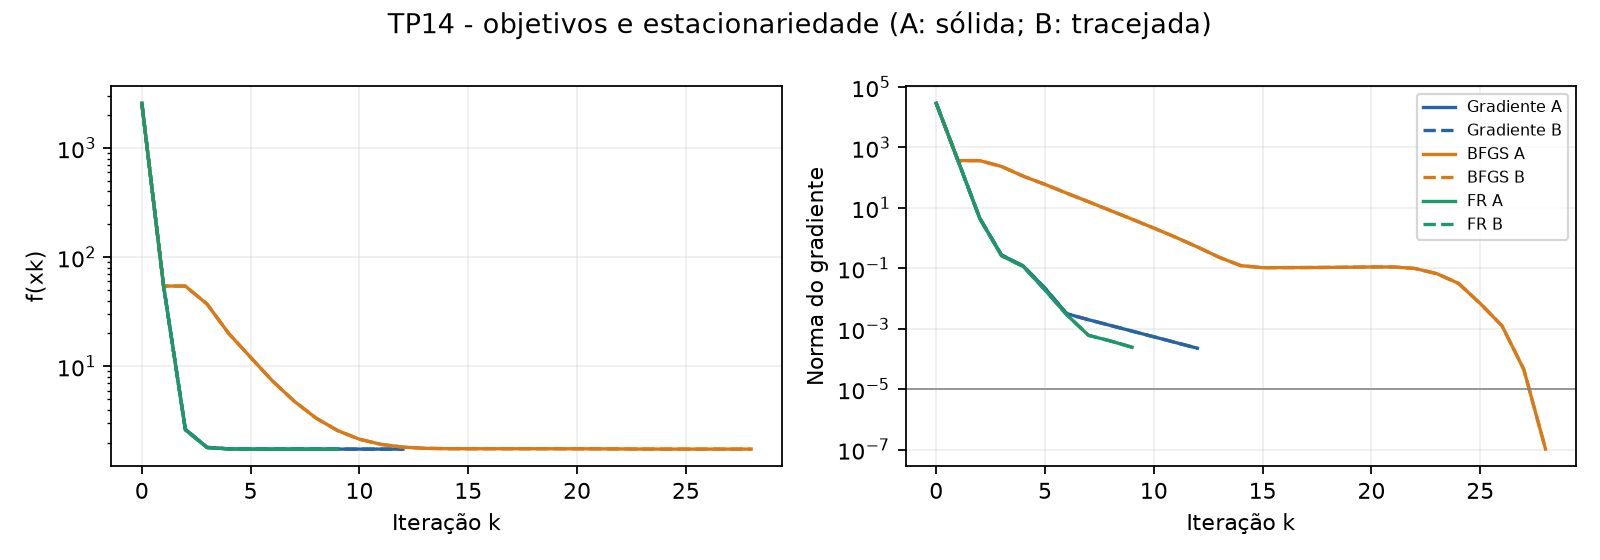

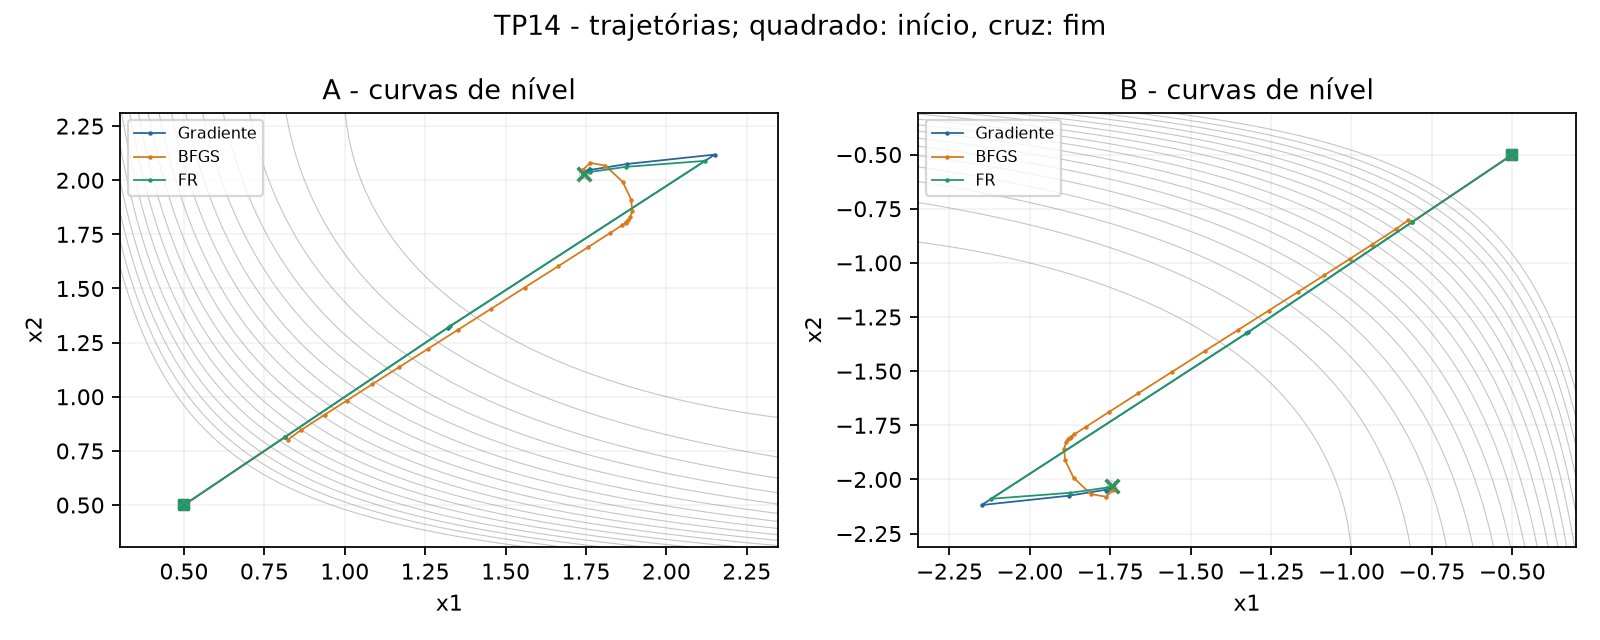

In [6]:
display(Image(filename='resultados/parte2/TP14_evolucao.png'))
display(Image(filename='resultados/parte2/TP14_trajetorias.png'))

## TP9 - interpretação

O mínimo global é (1;1), pois ambos os quadrados não negativos só se anulam nesse ponto. A equação g2=0 implica x2=x1² e então g1=0 implica x1=1: este é o único ponto estacionário, portanto nenhuma sela finita pode ser destino estacionário desta função. A reflexão do ponto inicial não produz simetria do objetivo.

No experimento principal o gradiente a partir de B atinge 1.000 iterações com f=0,12955 e norma 0,56842. A partir de A ele para por variação em 102 passos; isso não comprova a tolerância de gradiente. Mesmo com 20.000 passos, o gradiente clássico não atinge 10⁻⁵ em A ou B. O vale curvo é estreito e a Hessiana no mínimo tem autovalores aproximadamente 0,399936 e 10001,6001, condição 25008. Há alternância de direções em 91,1% (A) e 86,7% (B) dos pares do ensaio principal.

BFGS atinge a tolerância do gradiente em 61 passos (A) e 45 (B); FR em 442 (A) e 282 (B), com reinícios declarados. A reflexão mudou o custo de aproximação, sem evidência de mínimo diferente. Não se deve concluir que FR foi melhor porque parou antes no ensaio com variação: os gradientes finais não eram comparáveis.

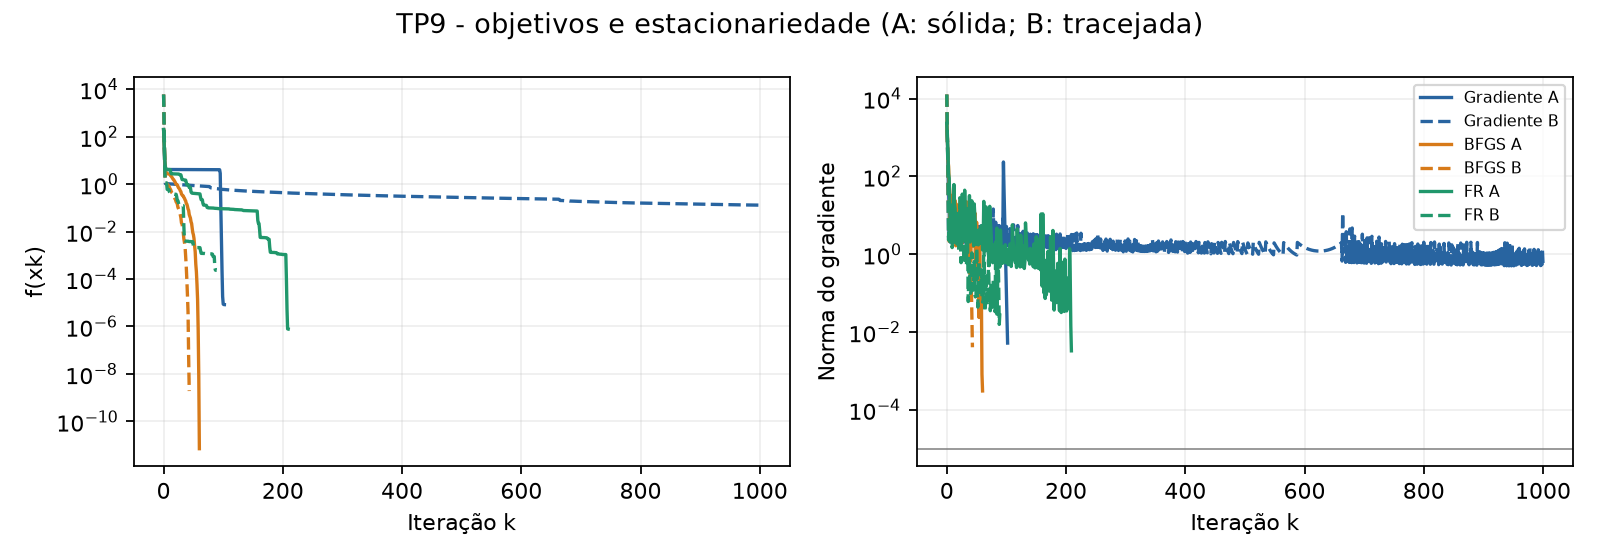

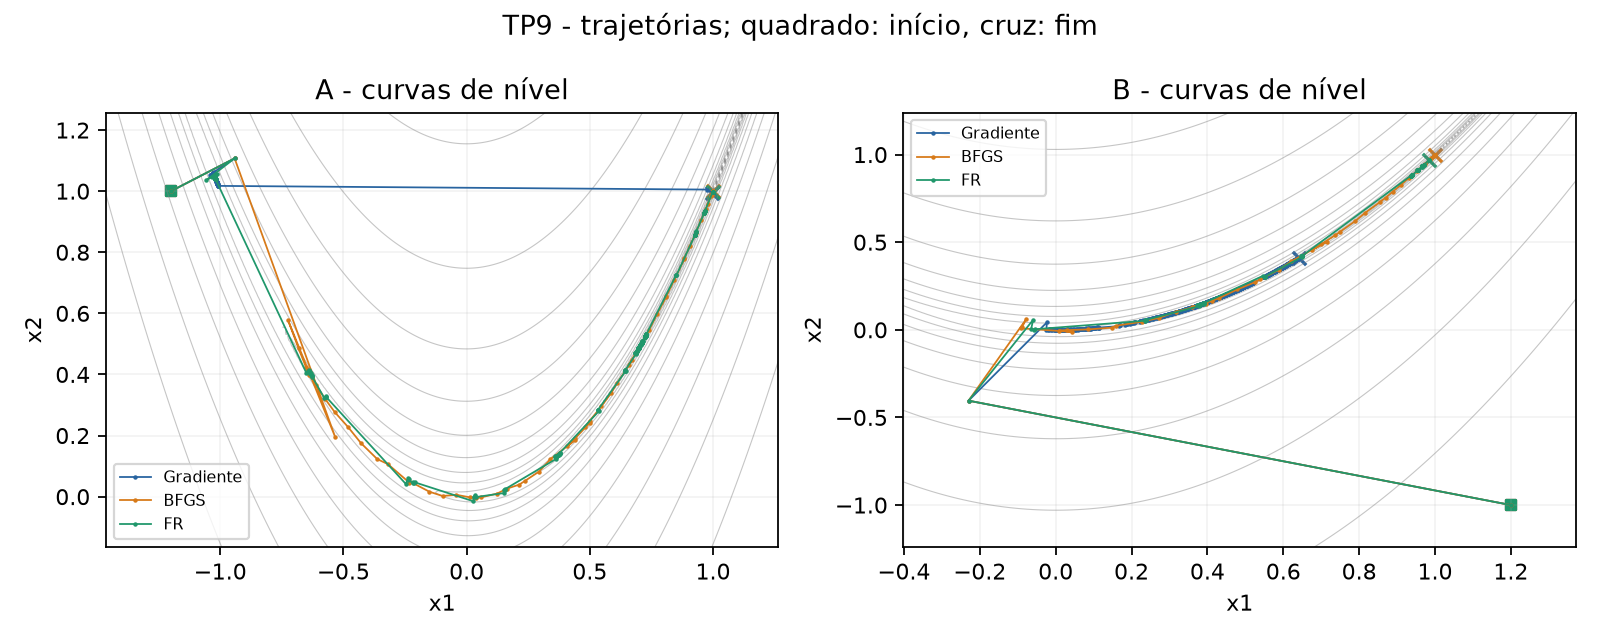

In [7]:
display(Image(filename='resultados/parte2/TP9_evolucao.png'))
display(Image(filename='resultados/parte2/TP9_trajetorias.png'))

## TP16 - interpretação

Apesar do rótulo G3, esta função é convexa: é soma de quadrados e quartas potências de funções afins. Seu mínimo único é zero na origem. Anular os quatro termos força x1=−10x2, x3=x4, x2=2x3 e x1=x4; logo todas as coordenadas são zero. Convexidade e unicidade excluem mínimos locais distintos ou selas estacionárias.

A Hessiana na origem tem autovalores 0, 0, 20 e 202. Ela é singular; a condição espectral é infinita e a função não é fortemente convexa na vizinhança do mínimo. Nas direções degeneradas o crescimento é de quarta ordem. Um gradiente pequeno pode ocorrer ainda a uma distância visível da origem, por isso os pontos finais também são apresentados.

A/B produzem trajetórias refletidas e exatamente os mesmos custos e contagens. O gradiente não atinge a tolerância em 20.000 passos. BFGS a atinge em 24 e FR em 611. No ensaio principal, BFGS e FR param por variação em 21 e 72 passos com gradientes acima do limiar. Os gráficos e os autovalores finais documentam degenerescência e lentidão; não indicam uma nova bacia ou sela.

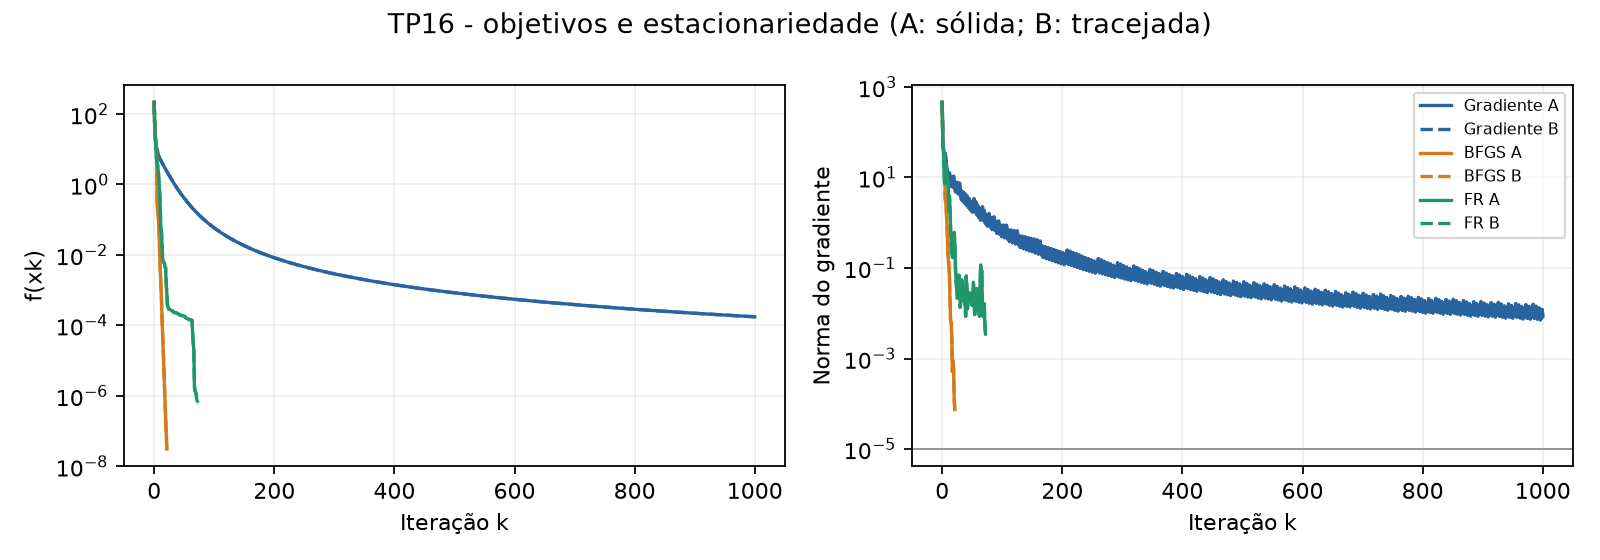

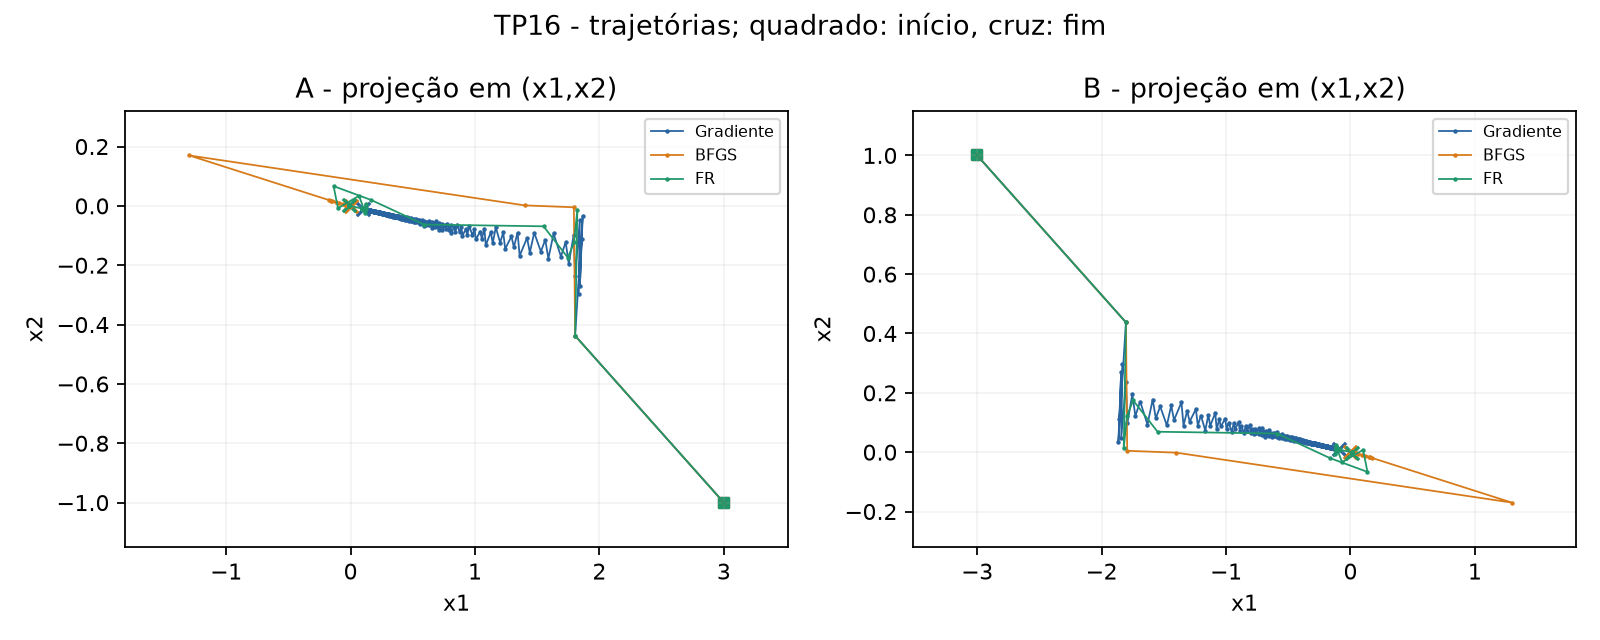

In [8]:
display(Image(filename='resultados/parte2/TP16_evolucao.png'))
display(Image(filename='resultados/parte2/TP16_trajetorias.png'))

## Refinamento por gradiente

Gerado independentemente com `python codigo/executar.py --tol-f 0 --max-iter 20000 --saida resultados/parte2_refinamento --sem-graficos`. Os 24 registros completos são preservados; esta célula somente os lê para evitar repetir os ensaios adicionais ao abrir o notebook.

In [9]:
from preparar_entrega import casos, REF
for nome in ['TP3','TP14','TP9','TP16']:
    for r in casos(REF,nome):
        print(nome,r['metodo'],r['ponto'],r['iteracoes'],r['norma_grad_final'],r['status'])

TP3 Gradiente A 42 9.359431478544818e-06 gradiente
TP3 Gradiente B 42 9.359431478544818e-06 gradiente
TP3 BFGS A 7 2.3049195810547545e-08 gradiente
TP3 BFGS B 7 2.3049195810547545e-08 gradiente
TP3 FR A 22 5.966223696803628e-06 gradiente
TP3 FR B 22 5.966223696803628e-06 gradiente
TP14 Gradiente A 20 6.937829820391075e-06 gradiente
TP14 Gradiente B 20 6.937829820391075e-06 gradiente
TP14 BFGS A 28 1.0355869559846193e-07 gradiente
TP14 BFGS B 28 1.0355869559846193e-07 gradiente
TP14 FR A 15 6.128605426973531e-06 gradiente
TP14 FR B 15 6.128605426973531e-06 gradiente


TP9 Gradiente A 20000 0.0002122925380671146 limite_iteracoes
TP9 Gradiente B 20000 0.007553115134084987 limite_iteracoes
TP9 BFGS A 61 2.79671193073713e-06 gradiente
TP9 BFGS B 45 1.981058459455143e-06 gradiente
TP9 FR A 442 7.709907302796541e-06 gradiente
TP9 FR B 282 3.900259929359069e-06 gradiente


TP16 Gradiente A 20000 0.00010314130076943267 limite_iteracoes
TP16 Gradiente B 20000 0.00010314130076943267 limite_iteracoes
TP16 BFGS A 24 4.3181392913948e-06 gradiente
TP16 BFGS B 24 4.3181392913948e-06 gradiente
TP16 FR A 611 8.617757270662846e-06 gradiente
TP16 FR B 611 8.617757270662846e-06 gradiente


## Manual e auditoria

Instalação: `python -m venv .venv`, depois `.venv/Scripts/python -m pip install -r requirements.txt`. Execução: `.venv/Scripts/python codigo/executar.py`. Verificações: `.venv/Scripts/python codigo/testar.py`. O comando `python codigo/preparar_entrega.py` regenera este notebook (sem saídas) e o PDF; reexecute o notebook depois.

Entrada: funções e pontos em `PROBLEMAS`; parâmetros na CLI ou `Parametros`. Uso direto: `minimizar(PROBLEMAS['TP9'], 'BFGS', [-1.2,1.], Parametros())`. Nunca iniciar o próximo método pelo resultado do anterior.

Saída: `resumo.csv` contém uma linha por execução; `TP*_Método_A/B.json[.gz]` contém toda a trajetória e passos; `metadados.json` registra parâmetros, versões e hashes; `validacao.json` contém evidências dos testes. Para gzip: `gzip.open(caminho, 'rt', encoding='utf-8')` e `json.load`.

Status: `gradiente` indica tolerância atingida; `variacao_objetivo` indica apenas pouca mudança; `limite_iteracoes` é inconclusivo; `falha_busca`, `valor_nao_finito` e `derivada_indefinida` são falhas explícitas. Os valores do objetivo são calculados com float64.

**Auditoria E001:** a primeira implementação permitia tol_grad=NaN: `NaN <= 0` é falso e `0 <= NaN` também. No mínimo do TP3 ela tentava busca com direção zero e retornava falha_busca. A correção valida finitude antes de avaliar a função. Os arquivos `resultados/auditoria/E001_antes.json` e `E001_depois.json` e 18 testes de regressão registram antes/depois. Não se trata de erro na derivada, nem afetou as execuções com tolerâncias finitas.

**Responsabilidades (distribuição declarada pelo usuário em 17/11/2026):**

| Responsável | Contribuição |
| --- | --- |
| Tiago Oliveira Lima (564988) | Parte 1: seleção dos trabalhos nos Encontros Universitários e elaboração dos resumos 1, 3 e 5. Parte 2: definição do escopo junto ao assistente (P001–P003); conferência das derivadas analíticas do TP3 e do TP9 contra o catálogo da primeira atividade; conferência da busca de Goldstein recuperada da Atividade 1 e de seus parâmetros (c = 0,1, α inicial = 1); análise dos resultados do TP3 e do TP9 (simetria das trajetórias, ziguezague do gradiente, vale estreito); execução dos comandos do Manual de Uso para checar a reprodutibilidade. |
| Noberto Frota Oliveira Nogueira (568044) | Parte 1: seleção dos trabalhos nos Encontros Universitários e elaboração dos resumos 2 e 4. Parte 2: conferência da atribuição de problemas e métodos (script de sorteio, semente 1133032) e dos pontos A/B; conferência das derivadas do TP14 e do TP16 e das referências analíticas (quatro mínimos do TP14, convexidade e Hessiana singular do TP16); revisão das salvaguardas do BFGS (condição de curvatura) e dos reinícios de Fletcher–Reeves; análise dos resultados do TP14 e do TP16 e redação da resposta à questão investigativa sobre bacias de atração; revisão do erro E001 e leitura final do relatório. |
| IA (Codex) | Apoio na localização e conferência de fontes, recuperação da Goldstein, implementação dos métodos e derivadas, execução de testes e ensaios, geração de gráficos, notebook e relatório e correção de E001. As contribuições humanas foram declaradas pelo usuário. |

A distribuição inclui a Parte 1; suas fichas não integram este notebook nem o relatório da Parte 2. Os registros de prompts, contribuições e E001 estão em `documentacao/auditoria/`.

Referência teórica: [Hager e Zhang, A Survey of Nonlinear Conjugate Gradient Methods, §§2 e 4](https://people.clas.ufl.edu/hager/files/cg_survey.pdf). As garantias de FR discutidas nessa fonte dependem de condições de busca que não são automaticamente impostas por Goldstein.